# 03 · Redes convolucionales

**Objetivo:** entender la convolución como un filtro con pesos compartidos (implementada desde
cero con im2col en `applied_dl.conv`), contar cuántos parámetros ahorra frente a una capa densa y
medir si una CNN realmente tolera mejor que un MLP los desplazamientos de la imagen.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
import torch
from applied_dl import Tensor
from applied_dl.conv import conv2d
from applied_dl.training import count_parameters, evaluate, fit
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

digits = load_digits()
images = digits.images / 16.0  # [1797, 8, 8]

## 1. Una convolución es un detector local

El mismo filtro 3×3 recorre toda la imagen. Con filtros de Sobel la salida resalta bordes
verticales u horizontales.

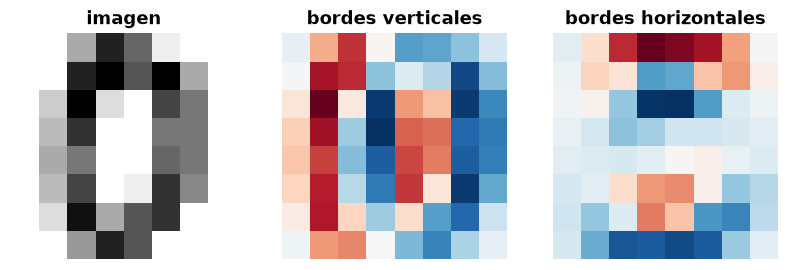

In [2]:
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)
kernels = Tensor(np.stack([sobel_x, sobel_x.T])[:, None])  # [2 filtros, 1 canal, 3, 3]
img = Tensor(images[:1, None])  # [1, 1, 8, 8]
out = conv2d(img, kernels, padding=1).data[0]
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, im, title in zip(
    axes,
    [images[0], out[0], out[1]],
    ["imagen", "bordes verticales", "bordes horizontales"],
    strict=True,
):
    ax.imshow(im, cmap="RdBu_r" if title != "imagen" else "gray_r")
    ax.set_title(title)
    ax.axis("off")

## 2. Pesos compartidos: cuántos parámetros

Mapear una imagen 28×28 a 32 mapas de 28×28:

In [3]:
dense = nn.Linear(28 * 28, 32 * 28 * 28)
conv = nn.Conv2d(1, 32, 3, padding=1)
print(f"capa densa equivalente: {count_parameters(dense):>12,} parámetros")
print(f"convolución 3×3:        {count_parameters(conv):>12,} parámetros")

capa densa equivalente:   19,694,080 parámetros
convolución 3×3:                 320 parámetros


La convolución asume dos cosas sobre las imágenes: **localidad** (un pixel se relaciona con
sus vecinos) y **equivarianza a traslaciones** (un borde es un borde en cualquier posición).
Esos supuestos son el *sesgo inductivo* que le da ventaja con pocos datos.

## 3. CNN vs. MLP en dígitos, y robustez a desplazamientos

Entrenamos ambos con los mismos datos y luego evaluamos en imágenes de test desplazadas
1 y 2 pixeles (con relleno de ceros).

In [4]:
Xtr, Xte, ytr, yte = train_test_split(
    images, digits.target, test_size=0.3, stratify=digits.target, random_state=0
)
Xtr_t, Xte_t = (
    torch.tensor(Xtr, dtype=torch.float32)[:, None],
    torch.tensor(Xte, dtype=torch.float32)[:, None],
)
ytr_t, yte_t = torch.tensor(ytr), torch.tensor(yte)
train_dl = DataLoader(
    TensorDataset(Xtr_t, ytr_t),
    batch_size=64,
    shuffle=True,
    generator=torch.Generator().manual_seed(0),
)
test_dl = DataLoader(TensorDataset(Xte_t, yte_t), batch_size=512)


def make_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 16, 3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(32 * 2 * 2, 10),
    )


def make_mlp():
    return nn.Sequential(nn.Flatten(), nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 10))


models = {}
for name, make in [("MLP", make_mlp), ("CNN", make_cnn)]:
    torch.manual_seed(0)
    m = make()
    fit(m, train_dl, test_dl, torch.optim.Adam(m.parameters(), lr=3e-3), epochs=40, patience=8)
    models[name] = m
    acc = evaluate(m, test_dl, torch.device("cpu"))[1]
    print(f"{name}: {count_parameters(m):,} parámetros, accuracy = {acc:.3f}")

MLP: 9,610 parámetros, accuracy = 0.983


CNN: 6,090 parámetros, accuracy = 0.985


In [5]:
def shift(x, dx, dy):
    out = torch.zeros_like(x)
    h, w = x.shape[-2:]
    out[..., max(dy, 0) : h + min(dy, 0), max(dx, 0) : w + min(dx, 0)] = x[
        ..., max(-dy, 0) : h - max(dy, 0), max(-dx, 0) : w - max(dx, 0)
    ]
    return out


shifts = [(0, 0), (1, 0), (0, 1), (1, 1), (2, 0), (2, 2)]
print(f"{'desplazamiento':>15}" + "".join(f"{n:>8}" for n in models))
for dx, dy in shifts:
    accs = []
    for m in models.values():
        m.eval()
        with torch.no_grad():
            accs.append((m(shift(Xte_t, dx, dy)).argmax(1) == yte_t).float().mean().item())
    print(f"{f'({dx}, {dy})':>15}" + "".join(f"{a:>8.3f}" for a in accs))

 desplazamiento     MLP     CNN
         (0, 0)   0.983   0.985
         (1, 0)   0.480   0.615
         (0, 1)   0.441   0.574
         (1, 1)   0.113   0.283
         (2, 0)   0.141   0.311
         (2, 2)   0.063   0.070


- Con 1 pixel de desplazamiento la CNN pierde bastante menos que el MLP (0.62 frente a 0.48 en
  horizontal), y lo hace con **menos** parámetros.
- Pero ambas caen mucho: en una imagen de 8×8, un pixel es el 12.5 % del ancho. Con 2 pixeles en
  diagonal las dos quedan cerca del azar.
- El MLP no tiene ninguna noción de vecindad: para él, un dígito desplazado es otro vector. La
  CNN tiene equivarianza en las convoluciones y algo de invariancia por el *max pooling*, pero
  su capa final densa vuelve a depender de la posición.

## Para llevar

- Convolución = filtro local con pesos compartidos; im2col la convierte en un producto de matrices.
- Muchos menos parámetros que una capa densa, y un sesgo inductivo adecuado para imágenes.
- La invariancia a traslaciones de una CNN es parcial: viene del pooling y del campo receptivo,
  no es gratis ni total. La aumentación de datos (proyecto) la refuerza.